# Performing WPT and visualise statistical metrics of nodesusing a graph
Here we use a graph presentation to display the results of WPT.

In [117]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [118]:

%matplotlib inline
sys.path.append("..")

from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.postprocess import plotting as plot
from wavelet_transform.utils.extensions import sci_form
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as sig



### Parameters

Specify parameters for synthetic data and wavelet transform

In [119]:
amp_sin_waves = 1 # amplitude of the sine waves added together to form the signal
sampling_rate = 50e6
phase = 0

frequency = 2e6

frequencies = [frequency] # create list of frequencies for synthetic data
time_period = 1/frequency
signal_duration = 10*time_period # duration of the signal is 10 times the test frequency
delay = 0#2*time_period # signal starts 2 time periods late
end = signal_duration#8*time_period # signal ends 2 time periods early

gaussian_noise_std = 0.01 # set the standard devaition of the noise

# generate data
data, t_plot = sd.sound_wave(
    amp_sin_waves, frequencies, phase, signal_duration, 
    sampling_rate, delay, end
    )

# add noise
gaussian_noise = sd.noise(gaussian_noise_std,signal_duration,sampling_rate)
data += gaussian_noise
data = sig.windows.hann(len(data))*data

# transform parameters
levels = 5
db_order = 10
wavelet = f'db{db_order}'
mode = "symmetric"


### Performing WP transform



In [120]:
# transform
transform_object = wpt.dwpt(data,levels, wavelet, 'constant')
final_level_nodes = transform_object.get_level(levels)
dwt_nodes = transform_object.dwt_results() # the dwt results can be extracted from the dwpt

# calculate energy
transform_object.calc_frequencies(sampling_rate)

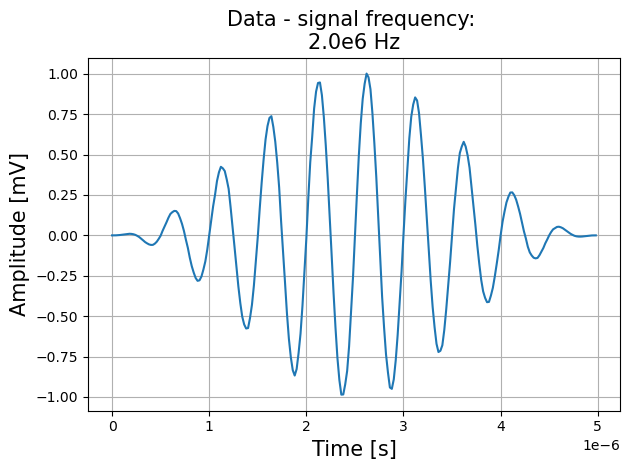

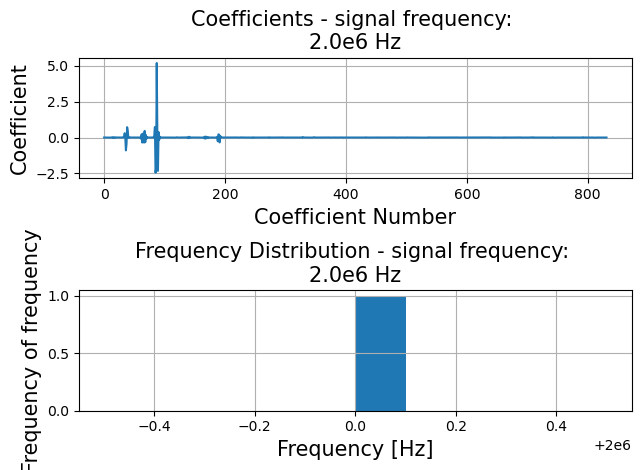

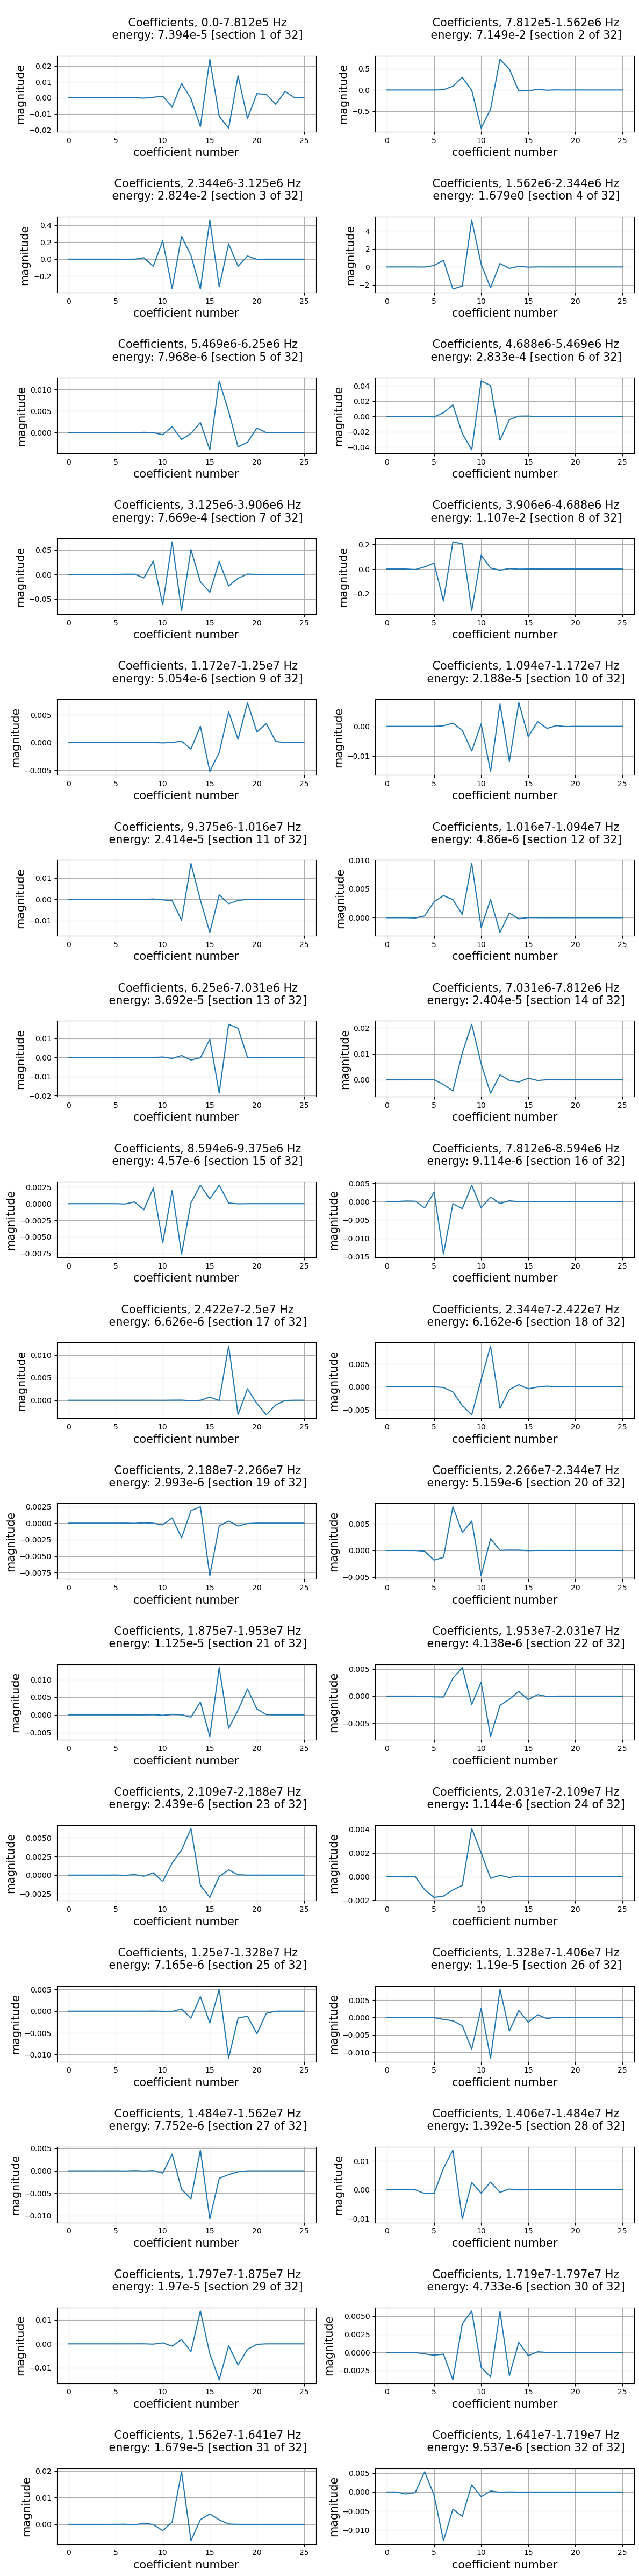

In [121]:
# set title
f = sci_form(frequency)
title = f"- signal frequency: \n{f} Hz"

# plot everything
plot.full_plot(
    final_level_nodes, data, t_plot, sampling_rate, 
    title, frequencies
    )

Calculating crest factor and energy

Wavelet transform

In [122]:
import pandas as pd

# Set display options
pd.set_option("display.max_rows", None)  # Show all rows
pd.set_option("display.max_columns", None)  # Show all columns


# WPT transform
tr_ob = wpt.dwpt(data, levels, wavelet, mode)
tr_ob.calc_frequencies(sampling_rate)

tr_ob.info(level=levels, order="freq").head()

,node number,energy,kurtosis,crest factor,skewness,frequency range
0,0,0.002143,21.340084,6.818629,4.349328,"(0.0, 7.812e5)"
1,1,0.142130,3.498035,0.433328,0.054059,"(7.812e5, 1.562e6)"
2,3,3.940481,4.510739,1.239845,0.481454,"(1.562e6, 2.344e6)"
3,2,0.102016,3.649153,2.052061,-0.535620,"(2.344e6, 3.125e6)"
4,6,0.002457,5.222004,3.465847,1.202587,"(3.125e6, 3.906e6)"


### Heisenberg visualisation

Making the heisenberg plot of the dwpt transform

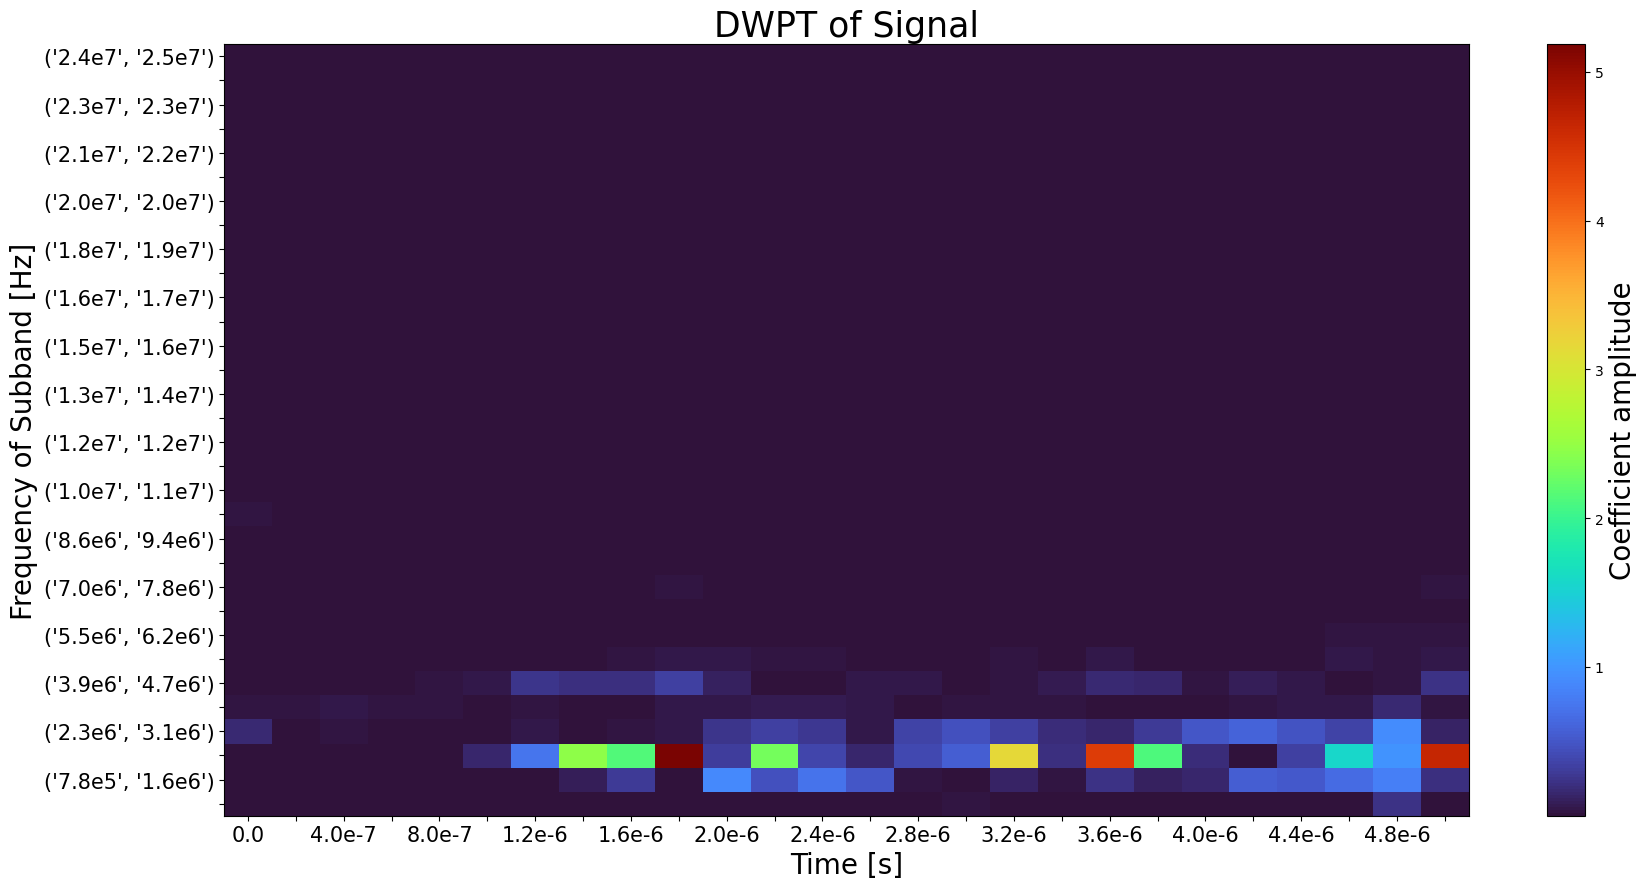

In [123]:
plot.heisenberg(tr_ob, max(t_plot))

In [124]:
for node in tr_ob.info(level=2,order='natural')['node number']:
    print(node)

0
1
2
3


In [125]:
graph_nodes = []
graph_edges = []

for i in range(levels,1,-1):
    for node in tr_ob.info(level=i,order='natural')['node number']:
        graph_nodes.append(( (i, node), {'energy':tr_ob.info(level=i,order='natural').loc[node]['energy']} ) )
        graph_edges.append( ((i,node),(i-1,node//2)) )
        
graph_nodes
# graph_edges[8]

[((5, 0), {'energy': 0.0021427449131240146}),
 ((5, 1), {'energy': 0.1421299566557064}),
 ((5, 2), {'energy': 0.10201631566334239}),
 ((5, 3), {'energy': 3.940480589463562}),
 ((5, 4), {'energy': 0.00014273428485441316}),
 ((5, 5), {'energy': 0.000784465189026366}),
 ((5, 6), {'energy': 0.002456502661580147}),
 ((5, 7), {'energy': 0.015988424068257307}),
 ((5, 8), {'energy': 6.1613521346502225e-06}),
 ((5, 9), {'energy': 2.8971270454388662e-05}),
 ((5, 10), {'energy': 4.743184204476772e-05}),
 ((5, 11), {'energy': 8.798064351044737e-06}),
 ((5, 12), {'energy': 4.316609215591188e-05}),
 ((5, 13), {'energy': 6.194200588575771e-05}),
 ((5, 14), {'energy': 1.2271274599238447e-05}),
 ((5, 15), {'energy': 1.0719774698392993e-05}),
 ((5, 16), {'energy': 7.115779061857222e-06}),
 ((5, 17), {'energy': 1.3232101987295838e-05}),
 ((5, 18), {'energy': 7.047714791874172e-06}),
 ((5, 19), {'energy': 6.181633379194469e-06}),
 ((5, 20), {'energy': 1.3541982669699841e-05}),
 ((5, 21), {'energy': 9.8247

In [126]:
import networkx as nx

In [127]:
G = nx.Graph()

In [128]:
graph_edges

[((5, 0), (4, 0)),
 ((5, 1), (4, 0)),
 ((5, 2), (4, 1)),
 ((5, 3), (4, 1)),
 ((5, 4), (4, 2)),
 ((5, 5), (4, 2)),
 ((5, 6), (4, 3)),
 ((5, 7), (4, 3)),
 ((5, 8), (4, 4)),
 ((5, 9), (4, 4)),
 ((5, 10), (4, 5)),
 ((5, 11), (4, 5)),
 ((5, 12), (4, 6)),
 ((5, 13), (4, 6)),
 ((5, 14), (4, 7)),
 ((5, 15), (4, 7)),
 ((5, 16), (4, 8)),
 ((5, 17), (4, 8)),
 ((5, 18), (4, 9)),
 ((5, 19), (4, 9)),
 ((5, 20), (4, 10)),
 ((5, 21), (4, 10)),
 ((5, 22), (4, 11)),
 ((5, 23), (4, 11)),
 ((5, 24), (4, 12)),
 ((5, 25), (4, 12)),
 ((5, 26), (4, 13)),
 ((5, 27), (4, 13)),
 ((5, 28), (4, 14)),
 ((5, 29), (4, 14)),
 ((5, 30), (4, 15)),
 ((5, 31), (4, 15)),
 ((4, 0), (3, 0)),
 ((4, 1), (3, 0)),
 ((4, 2), (3, 1)),
 ((4, 3), (3, 1)),
 ((4, 4), (3, 2)),
 ((4, 5), (3, 2)),
 ((4, 6), (3, 3)),
 ((4, 7), (3, 3)),
 ((4, 8), (3, 4)),
 ((4, 9), (3, 4)),
 ((4, 10), (3, 5)),
 ((4, 11), (3, 5)),
 ((4, 12), (3, 6)),
 ((4, 13), (3, 6)),
 ((4, 14), (3, 7)),
 ((4, 15), (3, 7)),
 ((3, 0), (2, 0)),
 ((3, 1), (2, 0)),
 ((3, 2), 

In [129]:
# G.add_nodes_from([(0,0,{'energy':gr1.loc[0]['energy']}),
#                   (1,0,{'energy':gr1.loc[1]['energy']}),
#                   (2,{'energy':gr2.loc[0]['energy']}),
#                   (3,{'energy':gr2.loc[1]['energy']}),
#                   (4,{'energy':gr2.loc[2]['energy']}),
#                   (5,{'energy':gr2.loc[3]['energy']}),
#                   ])
# G.add_edges_from([(0,2),(0,3),(1,4),(1,5)])

G.add_nodes_from(graph_nodes)


In [130]:
G.add_edges_from(graph_edges)


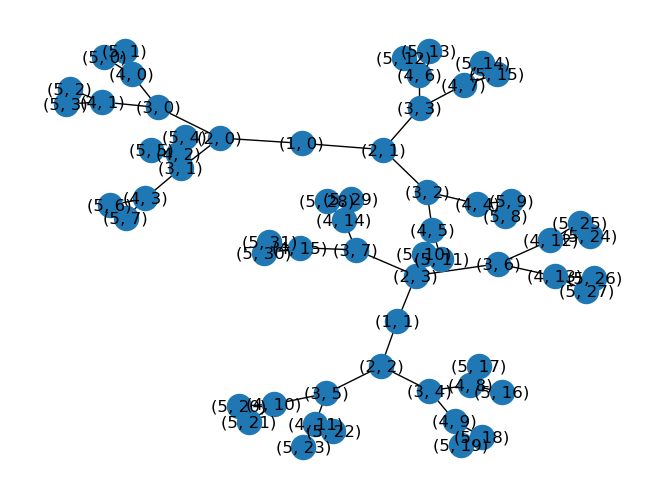

In [131]:
nx.draw(G, with_labels=True)
plt.show()

In [132]:
nx.get_node_attributes(G,'energy')

{(5, 0): 0.0021427449131240146,
 (5, 1): 0.1421299566557064,
 (5, 2): 0.10201631566334239,
 (5, 3): 3.940480589463562,
 (5, 4): 0.00014273428485441316,
 (5, 5): 0.000784465189026366,
 (5, 6): 0.002456502661580147,
 (5, 7): 0.015988424068257307,
 (5, 8): 6.1613521346502225e-06,
 (5, 9): 2.8971270454388662e-05,
 (5, 10): 4.743184204476772e-05,
 (5, 11): 8.798064351044737e-06,
 (5, 12): 4.316609215591188e-05,
 (5, 13): 6.194200588575771e-05,
 (5, 14): 1.2271274599238447e-05,
 (5, 15): 1.0719774698392993e-05,
 (5, 16): 7.115779061857222e-06,
 (5, 17): 1.3232101987295838e-05,
 (5, 18): 7.047714791874172e-06,
 (5, 19): 6.181633379194469e-06,
 (5, 20): 1.3541982669699841e-05,
 (5, 21): 9.82476489535568e-06,
 (5, 22): 4.9098463471981325e-06,
 (5, 23): 2.561739827537042e-06,
 (5, 24): 9.994059012660221e-06,
 (5, 25): 1.7703311770282625e-05,
 (5, 26): 2.0039182676519903e-05,
 (5, 27): 1.618473948784818e-05,
 (5, 28): 5.147778880520579e-05,
 (5, 29): 1.0810556743436146e-05,
 (5, 30): 3.0201591068

In [133]:
nx.draw(G, with_labels=True, node_size=[ nx.get_node_attributes(G, 'energy')[v] for v in G])
plt.show()

KeyError: (1, 0)